In [25]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 3)
RANDOM_STATE = 42

DATA_PATH = Path("cardio_cleaned.csv")
TARGET = "cardio"
NUMERIC_FEATURES = ["age_years","height","weight","ap_hi","ap_lo","bmi"]
CATEGORICAL_FEATURES = ["gender", "cholesterol","gluc","smoke","alco","active",'ap_hi_category', 
    'ap_lo_category', 
    'height_category', 
    'ap_lo_original',  
    'weight_category']
ID_COLUMNS = ["id"] if "id" in pd.read_csv(DATA_PATH, nrows=0).columns else []
DATETIME_COLUMNS = []
EXCLUDED_COLUMNS = ["age"] if "age" in pd.read_csv(DATA_PATH, nrows=0).columns else []
TARGET_LABELS = { 0: "No cardiovascular disease", 1: "Cardiovascular disease"}
POSITIVE_CLASS = 1

ORDERED_FEATURE = "age_years"
ORDERED_EDGES = [20, 30, 40, 50, 60, 70]
INTERACTION_FEATURES = ("age_years", "weight")
CATEGORICAL_PAIR = ("gender", "cholesterol")
PLACEHOLDER_VALUES = {}

MAX_SCATTER_ROWS = 6000
MIN_GROUP_SIZE = 30

In [26]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {DATA_PATH}. "
        "Make sure cardio_cleaned.csv is in the same folder as this notebook."
    )

raw = pd.read_csv(DATA_PATH)

print(f"Loaded {DATA_PATH.name}: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())
raw.info()

Loaded cardio_cleaned.csv: 68,666 rows × 19 columns


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,...,age_years,bmi,height_category,weight_category,ap_hi_category,ap_lo_category,ap_lo_original
0,18393,2,168.0,62.0,110,80,1,...,50.4,21.967,Normal height,Normal range,Normal IQR range,Within IQR range,80
1,20228,1,156.0,85.0,140,90,3,...,55.4,34.928,Normal height,Normal range,Normal IQR range,Within IQR range,90
2,18857,1,165.0,64.0,130,70,3,...,51.6,23.508,Normal height,Normal range,Normal IQR range,Within IQR range,70
3,17623,2,169.0,82.0,150,100,1,...,48.2,28.710,Normal height,Normal range,Normal IQR range,Within IQR range,100
4,17474,1,156.0,56.0,100,60,1,...,47.8,23.011,Normal height,Normal range,Normal IQR range,Low outlier,60


<class 'pandas.DataFrame'>
RangeIndex: 68666 entries, 0 to 68665
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              68666 non-null  int64  
 1   gender           68666 non-null  int64  
 2   height           68666 non-null  float64
 3   weight           68666 non-null  float64
 4   ap_hi            68666 non-null  int64  
 5   ap_lo            68666 non-null  int64  
 6   cholesterol      68666 non-null  int64  
 7   gluc             68666 non-null  int64  
 8   smoke            68666 non-null  int64  
 9   alco             68666 non-null  int64  
 10  active           68666 non-null  int64  
 11  cardio           68666 non-null  int64  
 12  age_years        68666 non-null  float64
 13  bmi              68666 non-null  float64
 14  height_category  68666 non-null  str    
 15  weight_category  68666 non-null  str    
 16  ap_hi_category   68666 non-null  str    
 17  ap_lo_category   68666 

In [27]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_n": raw.isna().sum(),
    "unique_nonmissing": raw.nunique(),
    "examples": [", ".join(map(str, raw[c].dropna().unique()[:5])) for c in raw.columns]
})
display(profile)


roles = {"target": [TARGET], "numerical": NUMERIC_FEATURES,
         "categorical": CATEGORICAL_FEATURES, "ID": ID_COLUMNS,
         "datetime": DATETIME_COLUMNS, "excluded": EXCLUDED_COLUMNS}
assigned = [c for cols in roles.values() for c in cols]
assert len(assigned) == len(set(assigned)), "A column has more than one role."
assert set(assigned) == set(raw.columns), "Review missing, extra, or unassigned column names."
assert all(pd.api.types.is_numeric_dtype(raw[c]) for c in NUMERIC_FEATURES), "Review numeric parsing."
assert not raw.empty, "The dataset has no rows."
display(pd.DataFrame([(c, role) for role, cols in roles.items() for c in cols],
                     columns=["column", "analysis_role"]))

,dtype,missing_n,unique_nonmissing,examples
age,int64,0,8065,"18393, 20228, 18857, 17623, 17474"
gender,int64,0,2,"2, 1"
height,float64,0,85,"168.0, 156.0, 165.0, 169.0, 151.0"
weight,float64,0,275,"62.0, 85.0, 64.0, 82.0, 56.0"
ap_hi,int64,0,106,"110, 140, 130, 150, 100"
ap_lo,int64,0,71,"80, 90, 70, 100, 60"
cholesterol,int64,0,3,"1, 3, 2"
gluc,int64,0,3,"1, 2, 3"
smoke,int64,0,2,"0, 1"
alco,int64,0,2,"0, 1"


,column,analysis_role
0,cardio,target
1,age_years,numerical
2,height,numerical
3,weight,numerical
4,ap_hi,numerical
5,ap_lo,numerical
6,bmi,numerical
7,gender,categorical
8,cholesterol,categorical
9,gluc,categorical


**Question:** could missingness, duplicate rows, or recording practices distort our conclusions?

,missing_n,missing_pct
age,0,0.0
gender,0,0.0
height,0,0.0
weight,0,0.0
ap_hi,0,0.0
ap_lo,0,0.0
cholesterol,0,0.0
gluc,0,0.0
smoke,0,0.0
alco,0,0.0


Repeated rows beyond the first identical row: 24
Constant/all-missing columns: []


""


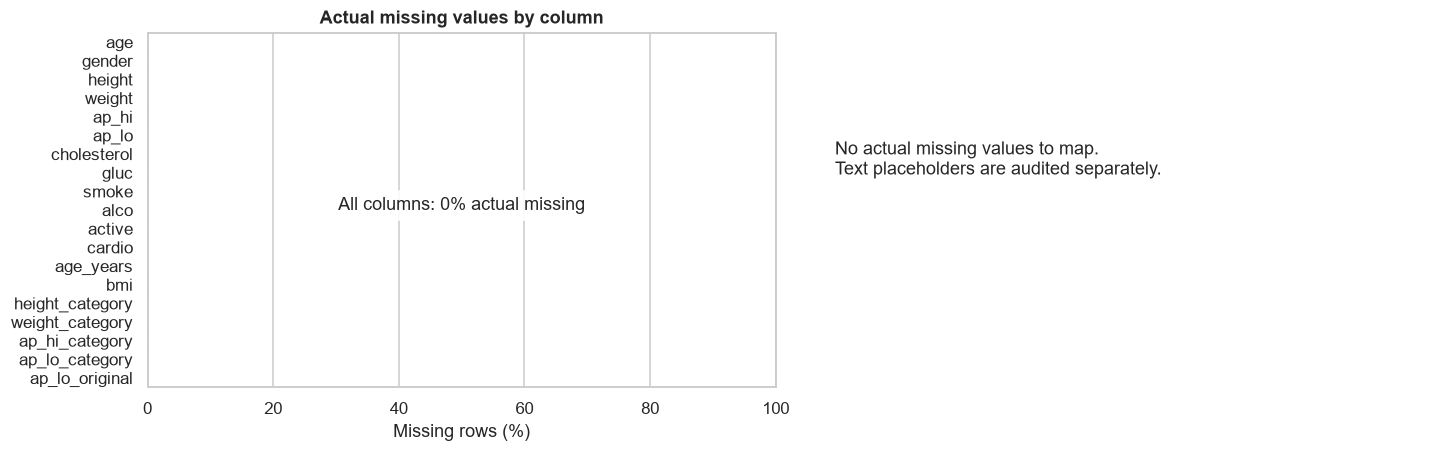

In [28]:
missing = raw.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({"missing_n": missing, "missing_pct": missing / len(raw) * 100})
display(quality)
print(f"Repeated rows beyond the first identical row: {raw.duplicated().sum():,}")
print("Constant/all-missing columns:", raw.columns[raw.nunique(dropna=True) <= 1].tolist())

placeholder_rows = []
for col, values in PLACEHOLDER_VALUES.items():
    if col in raw:
        for value in values:
            n = int(raw[col].eq(value).sum())
            placeholder_rows.append({"column": col, "recorded_value": value,
                                     "rows": n, "percent": 100 * n / len(raw)})
display(pd.DataFrame(placeholder_rows))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
missing_pct = quality["missing_pct"].rename_axis("column").reset_index()
sns.barplot(data=missing_pct, x="missing_pct", y="column", color="#3783a5", ax=axes[0])
axes[0].set(title="Actual missing values by column", xlabel="Missing rows (%)", ylabel="")
axes[0].set_xlim(0, 100)
if missing.sum() == 0:
    axes[0].text(0.5, 0.5, "All columns: 0% actual missing", transform=axes[0].transAxes,
                 ha="center", bbox={"facecolor":"white", "alpha":0.9})
    axes[1].axis("off")
    axes[1].text(0.05, 0.6, "No actual missing values to map.\nText placeholders are audited separately.",
                 transform=axes[1].transAxes)
else:
    missing_sample = raw.sample(min(300, len(raw)), random_state=RANDOM_STATE)
    sns.heatmap(missing_sample.isna(), cbar=False, yticklabels=False, ax=axes[1],
                cmap=["#e7f0f5", "#ce5d45"], vmin=0, vmax=1)
    axes[1].set(title="Missingness pattern: random sample, up to 300 rows", ylabel="Sampled rows")
plt.show()

In [29]:
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}")
    display(raw[col].value_counts(dropna=False).rename("rows").to_frame())

if NUMERIC_FEATURES:
    display(raw[NUMERIC_FEATURES].describe().T)
    display(pd.DataFrame({
        "most_frequent_value": [raw[c].mode().iloc[0] if not raw[c].mode().empty else np.nan
                                for c in NUMERIC_FEATURES],
        "frequency_pct": [100 * raw[c].value_counts(normalize=True).iloc[0]
                          if raw[c].notna().any() else np.nan for c in NUMERIC_FEATURES]
    }, index=NUMERIC_FEATURES))


gender


,rows
gender,
1,44727
2,23939



cholesterol


,rows
cholesterol,
1,51497
2,9300
3,7869



gluc


...

,rows
ap_lo_original,
80,34736
90,14269
70,10218
100,4070
60,2716
...,...
56,1
107,1
122,1



weight_category


,rows
weight_category,
Normal range,66927
Higher than usual,1696
Lower than usual,43


,count,mean,std,min,25%,50%,75%,max
age_years,68666.0,53.291,6.758,29.600,48.300,53.900,58.400,64.900
height,68666.0,164.395,7.977,100.000,159.000,165.000,170.000,207.000
weight,68666.0,74.122,14.324,30.000,65.000,72.000,82.000,200.000
ap_hi,68666.0,126.670,16.681,70.000,120.000,120.000,140.000,240.000
ap_lo,68666.0,81.293,9.383,40.000,80.000,80.000,90.000,120.000
bmi,68666.0,27.474,5.358,10.727,23.875,26.346,30.119,152.552


,most_frequent_value,frequency_pct
age_years,56.000,1.095
height,165.000,8.380
weight,65.000,5.522
ap_hi,120.000,40.282
ap_lo,80.000,50.587
bmi,23.875,1.356


In [30]:
print(f"Rows excluded from class comparisons because target is missing: {raw[TARGET].isna().sum():,}")
df = raw.loc[raw[TARGET].notna()].copy()
assert not df.empty, "No labeled rows remain."
if NUMERIC_FEATURES:
    assert not np.isinf(df[NUMERIC_FEATURES].to_numpy(dtype=float)).any(), "Investigate infinite values."
    NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if df[c].notna().any()]
    print("Numerical features with at least one observed value:", NUMERIC_FEATURES)

observed_classes = sorted(df[TARGET].unique(), key=str)
label_lookup = {value: str(TARGET_LABELS.get(value, value))for value in observed_classes}

assert len(set(label_lookup.values())) == len(label_lookup), "Target display labels must be distinct."
CLASS_COL = "__target_label__"
assert CLASS_COL not in df.columns
df[CLASS_COL] = df[TARGET].map(label_lookup)
class_order = [label_lookup[v] for v in observed_classes]
class_colors = dict(zip(class_order, sns.color_palette("colorblind", len(class_order))))
IS_BINARY = len(observed_classes) == 2 and POSITIVE_CLASS in observed_classes

for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype("string").fillna("<Missing>")
category_orders = {c: df[c].value_counts().index.tolist() for c in CATEGORICAL_FEATURES}
print(f"Analysis population: {len(df):,} rows; classes: {class_order}")


Rows excluded from class comparisons because target is missing: 0
Numerical features with at least one observed value: ['age_years', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']
Analysis population: 68,666 rows; classes: ['No cardiovascular disease', 'Cardiovascular disease']


In [31]:
categorical_columns = CATEGORICAL_FEATURES.copy()
numerical_columns = NUMERIC_FEATURES.copy()
class_col = CLASS_COL

def subplot_grid(n, ncols=2, width=6, height=4):
    """Return a figure and n usable axes; hide any unused panels."""
    ncols = min(ncols, max(1, n))
    nrows = int(np.ceil(max(1, n) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows),
                             squeeze=False, constrained_layout=True)
    flat = axes.ravel()
    for ax in flat[n:]:
        ax.set_visible(False)
    return fig, flat[:n]

def label_bars(ax, fmt="%.1f"):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=8, padding=3)
    ax.margins(y=0.18)

**Question:** are the classes equally represented?

In [32]:
target_counts = df[CLASS_COL].value_counts().reindex(class_order)
target_summary = pd.DataFrame({"rows": target_counts, "percent": target_counts/len(df)*100})
print(target_counts)
print(target_summary)

__target_label__
No cardiovascular disease    34697
Cardiovascular disease       33969
Name: count, dtype: int64
                            rows  percent
__target_label__                         
No cardiovascular disease  34697    50.53
Cardiovascular disease     33969    49.47


C:\Users\mg050\AppData\Local\Temp\ipykernel_13780\658464438.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=CLASS_COL, order=class_order, palette=class_colors,


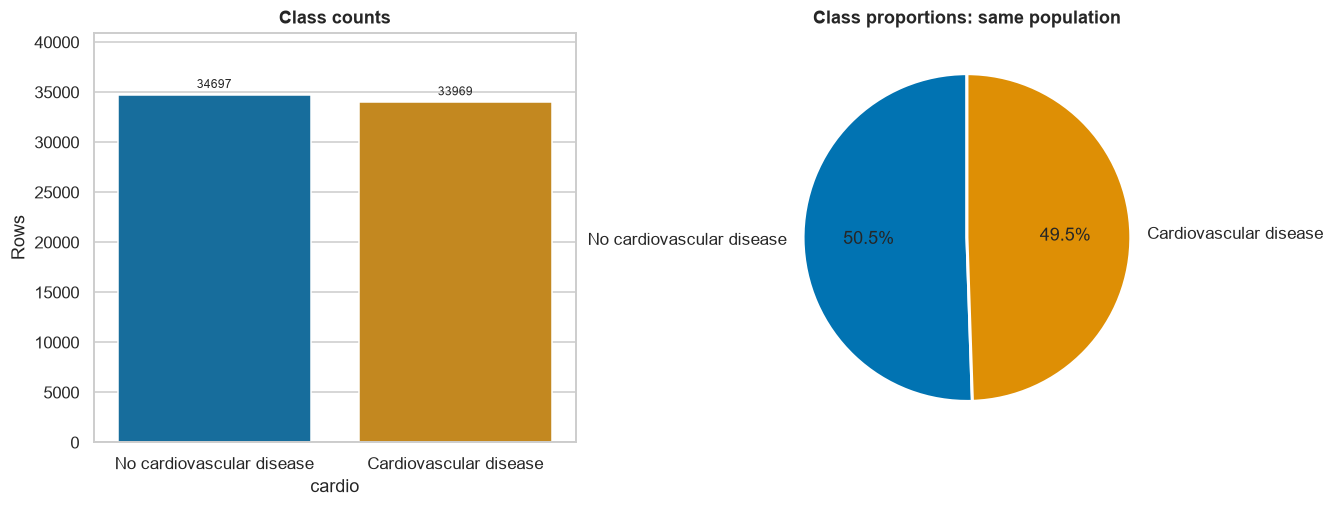

Majority-class baseline on these rows: 50.53%


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
sns.countplot(data=df, x=CLASS_COL, order=class_order, palette=class_colors,
              legend=False, ax=axes[0])
axes[0].set(title="Class counts", xlabel=TARGET, ylabel="Rows")
label_bars(axes[0], "%.0f")
if len(class_order) <= 5:
    axes[1].pie(target_counts, labels=class_order, autopct="%1.1f%%", startangle=90,
                colors=[class_colors[c] for c in class_order],
                wedgeprops={"edgecolor":"white", "linewidth":2})
    axes[1].set_title("Class proportions: same population")
else:
    axes[1].axis("off")
    axes[1].text(0, 0.5, "Pie omitted: use the countplot and percentage table for many classes.")
plt.show()
print(f"Majority-class baseline on these rows: {target_counts.max()/len(df):.2%}")

**Question:** where are values concentrated, how wide is the range, and are there skewness, gaps, spikes, or multiple peaks?

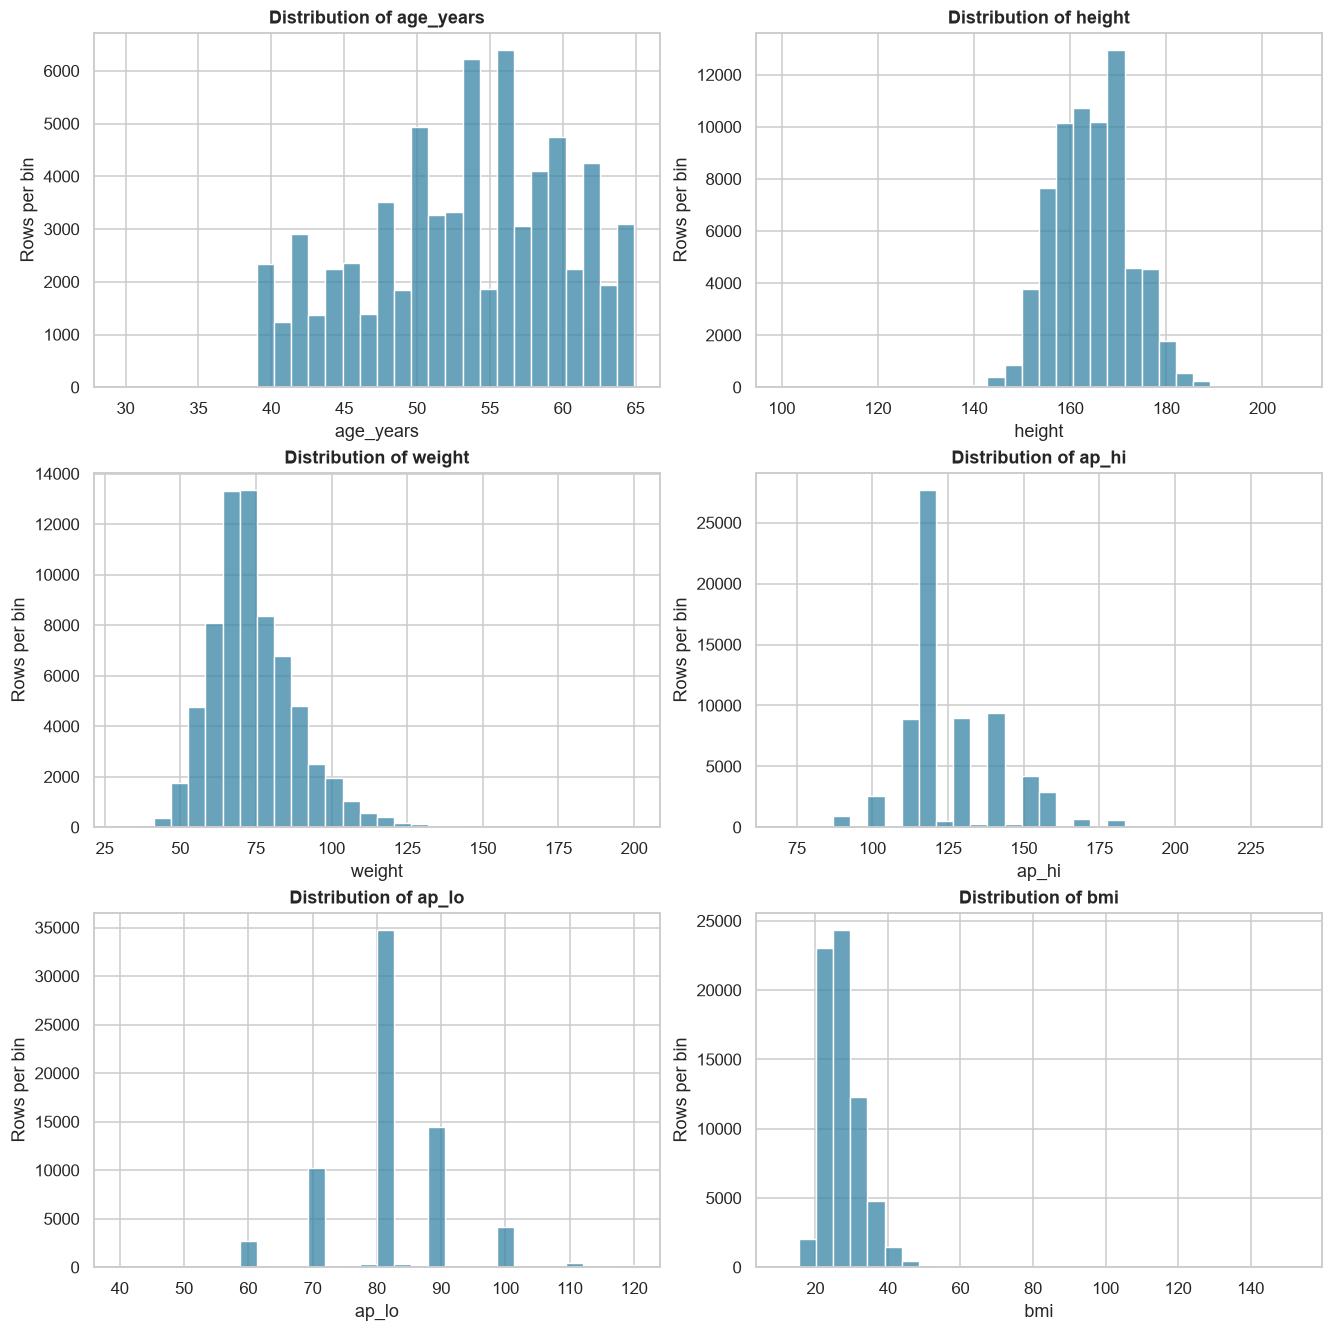

In [34]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(data=df, x=col, bins=30, color="#3783a5", ax=ax)
        ax.set(title=f"Distribution of {col}", ylabel="Rows per bin")
    plt.show()

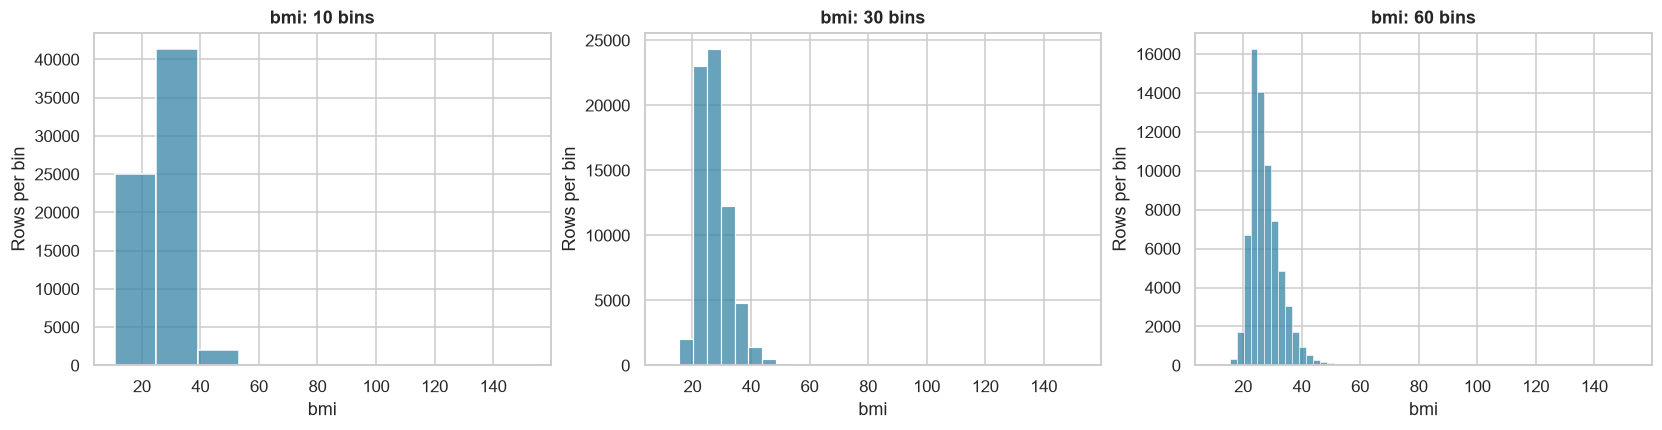

In [35]:
if NUMERIC_FEATURES:
    example_feature = "bmi" if "bmi" in NUMERIC_FEATURES else NUMERIC_FEATURES[0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True, constrained_layout=True)
    for ax, bins in zip(axes, [10, 30, 60]):
        sns.histplot(data=df, x=example_feature, bins=bins, color="#3783a5", ax=ax)
        ax.set(title=f"{example_feature}: {bins} bins", ylabel="Rows per bin")
    plt.show()

**Question:** which categories are common or rare, and is an unknown category substantial?

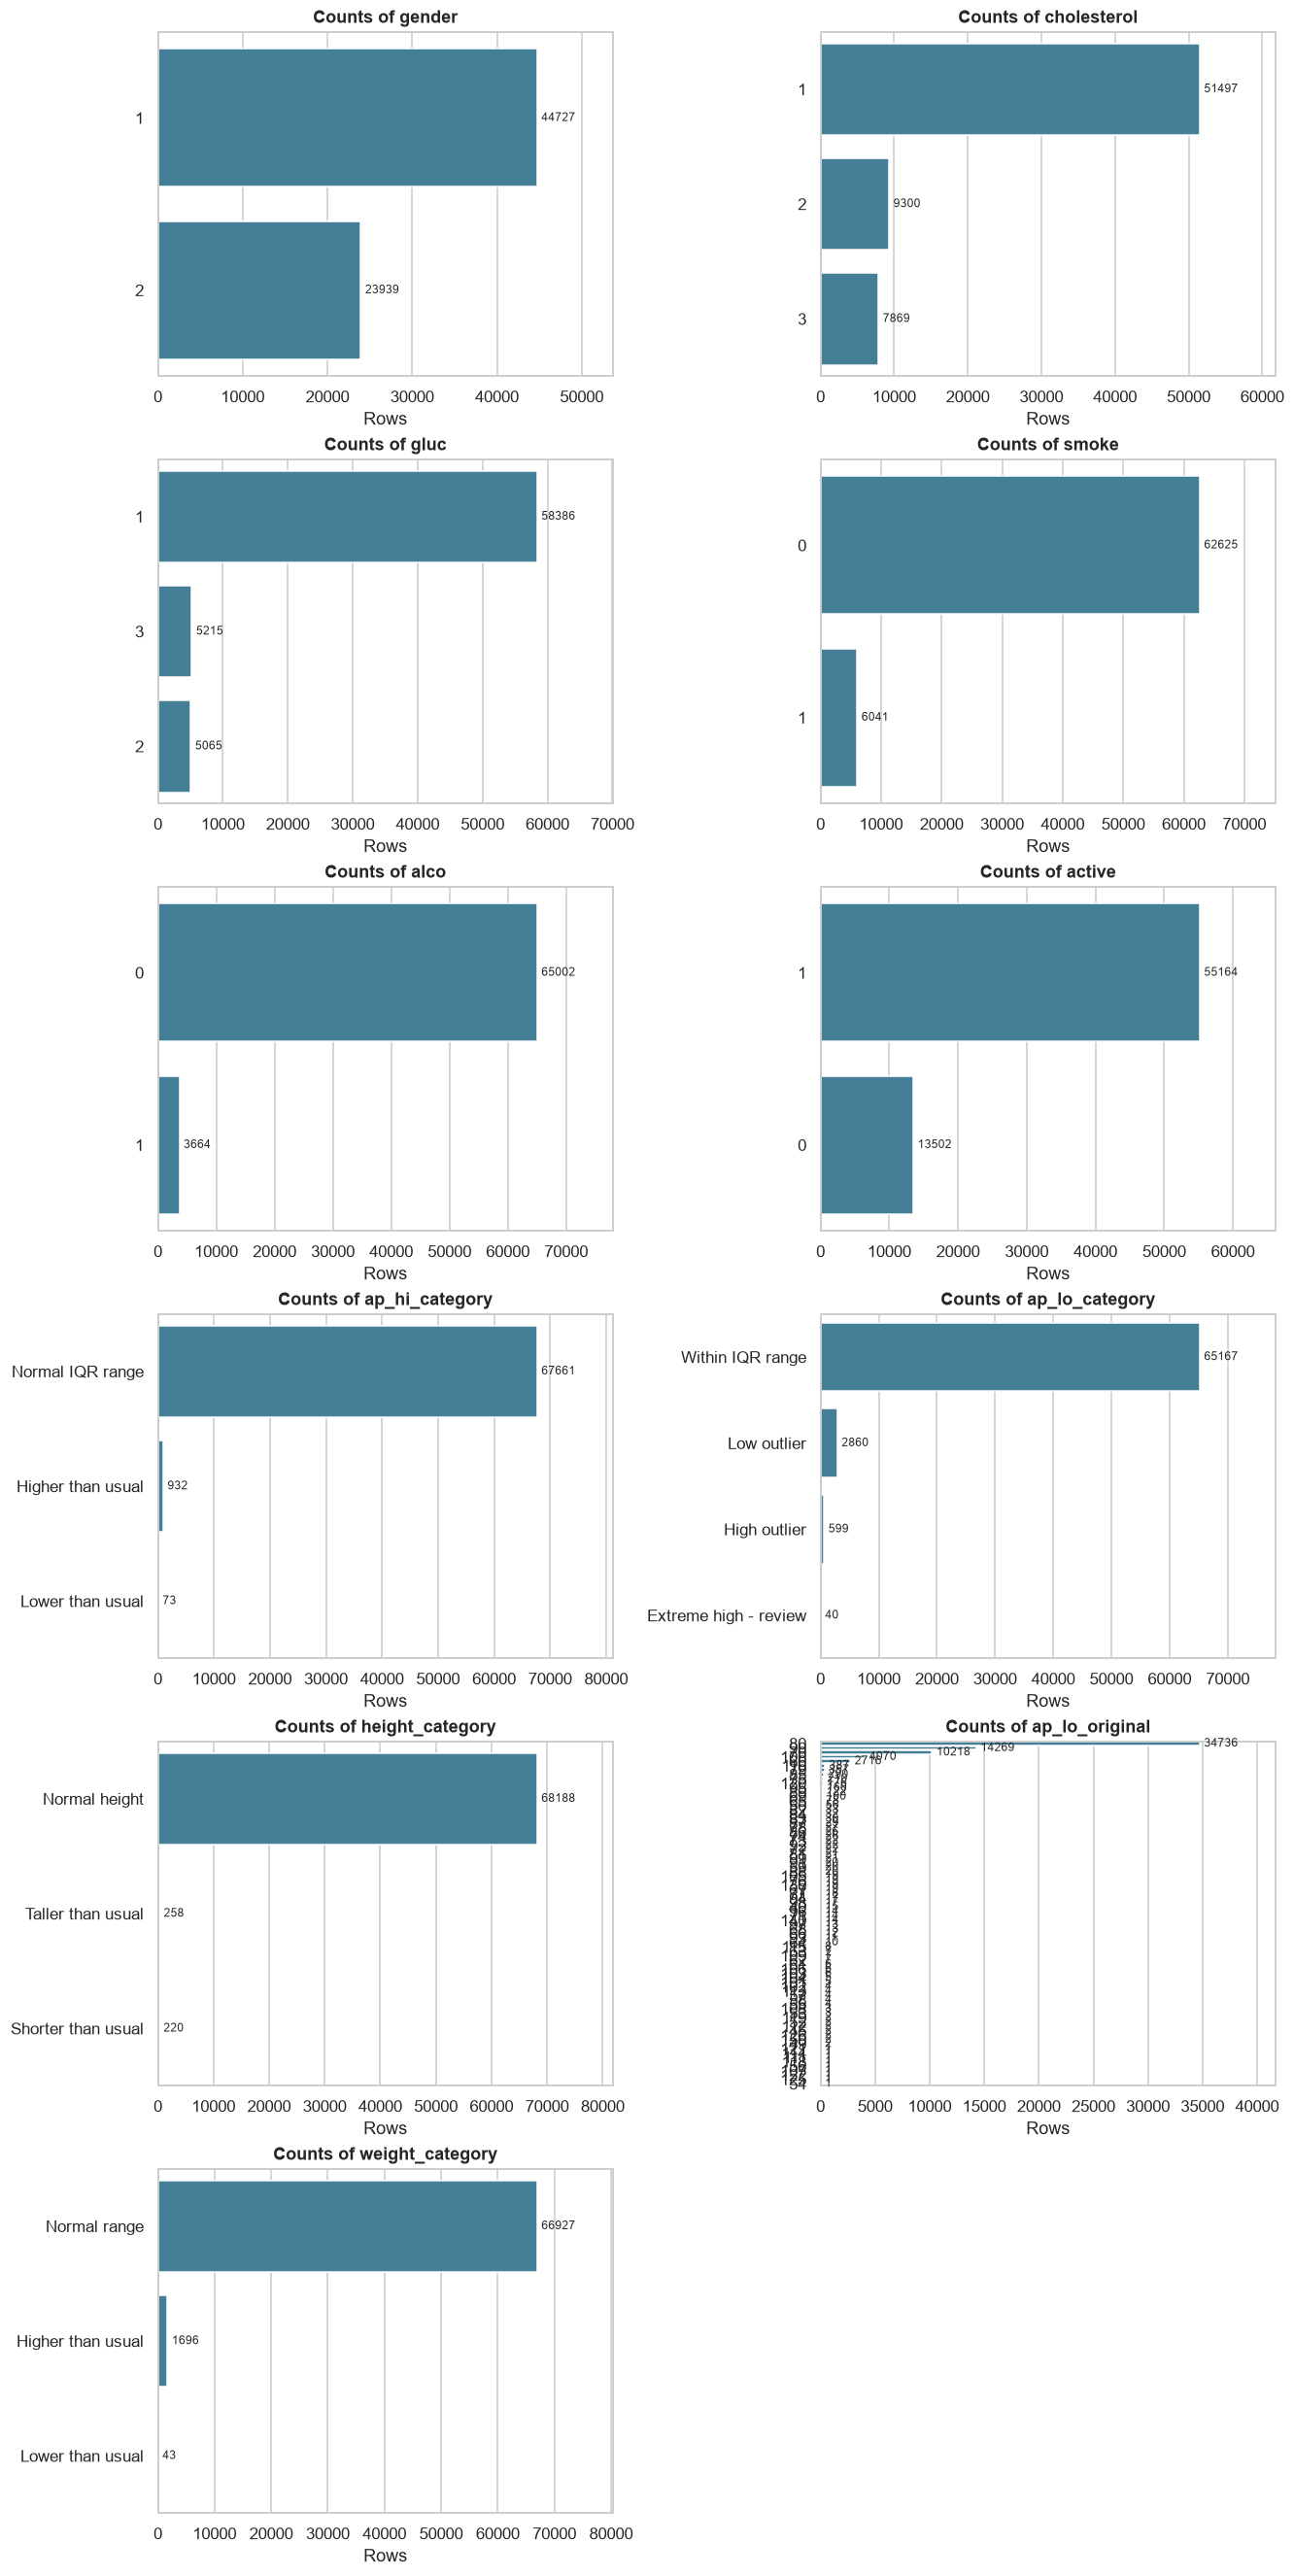

In [36]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES))
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, y=col, order=category_orders[col], color="#3783a5", ax=ax)
        ax.set(title=f"Counts of {col}", xlabel="Rows", ylabel="")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", fontsize=8, padding=3)
        ax.margins(x=0.2)
    plt.show()

**Question:** which measurements have unusual values relative to their distribution?

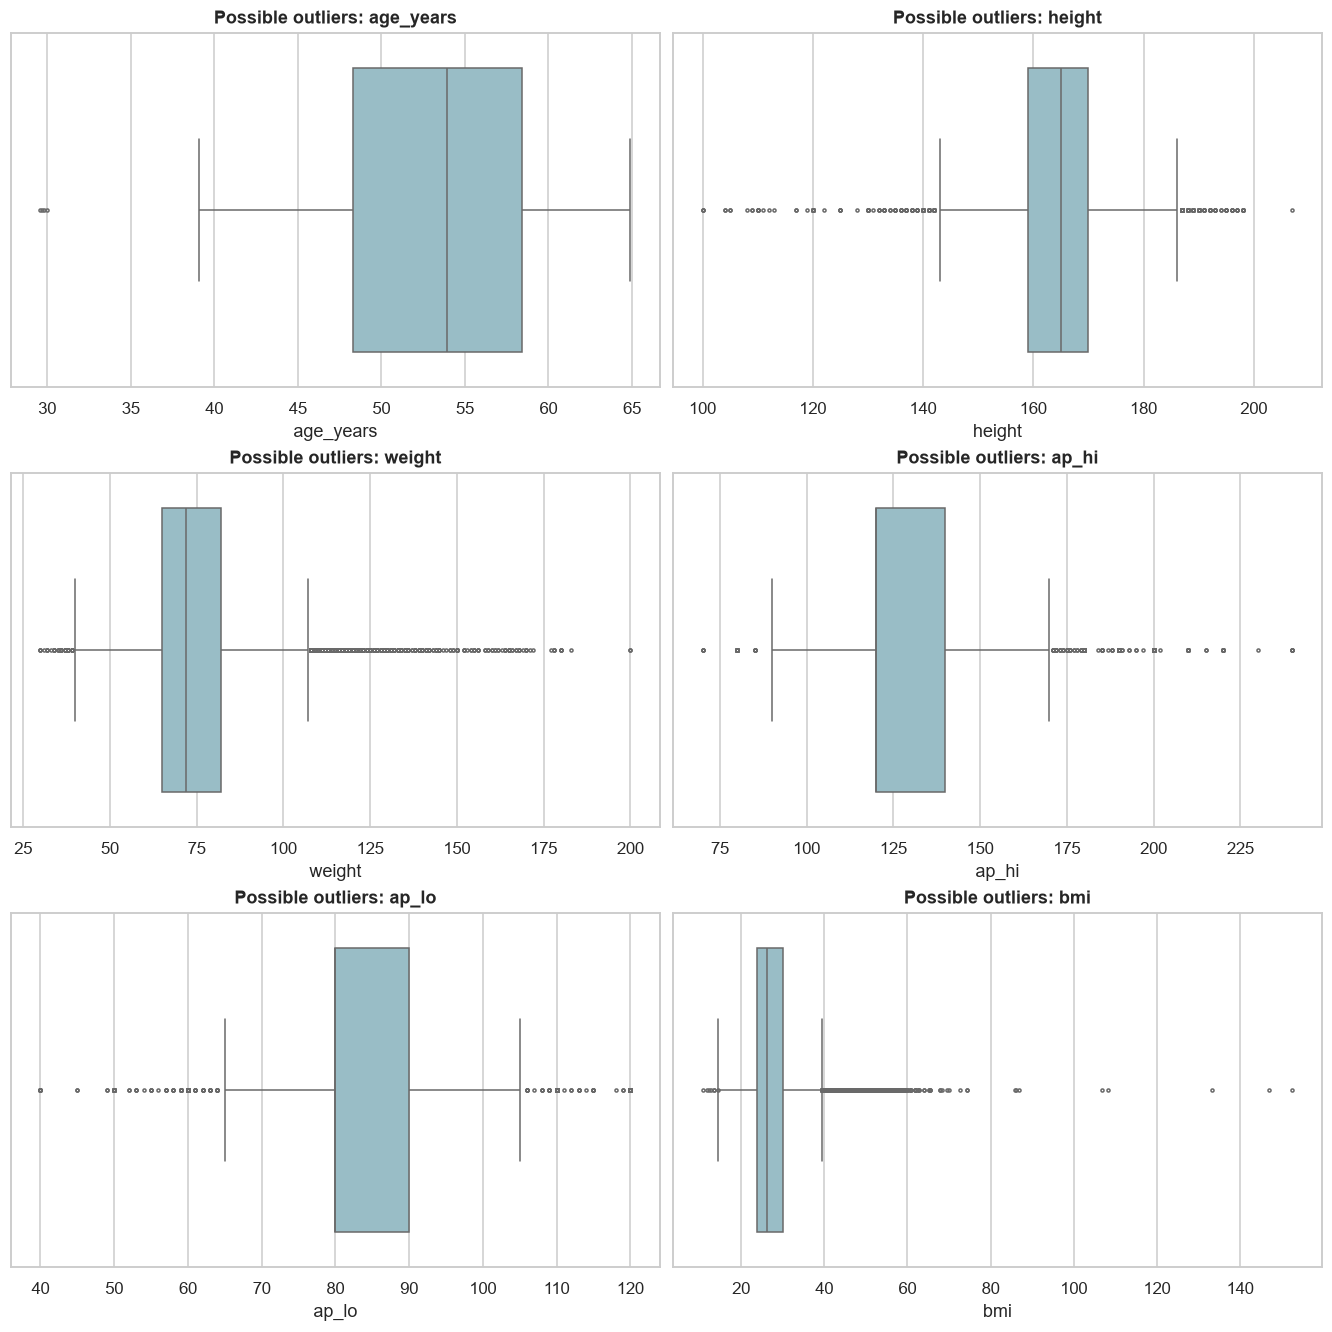

,feature,Q1,Q3,IQR,lower_fence,upper_fence,flagged_n,observed_n,flagged_pct
0,age_years,48.300,58.400,10.100,33.150,73.550,4,68666,0.006
1,height,159.000,170.000,11.000,142.500,186.500,478,68666,0.696
2,weight,65.000,82.000,17.000,39.500,107.500,1739,68666,2.533
3,ap_hi,120.000,140.000,20.000,90.000,170.000,1005,68666,1.464
4,ap_lo,80.000,90.000,10.000,65.000,105.000,3499,68666,5.096
5,bmi,23.875,30.119,6.244,14.509,39.486,1997,68666,2.908


Flagged rows have been retained.


In [37]:
outlier_rows = []
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(data=df, x=col, color="#91c2ce", fliersize=2, ax=ax)
        ax.set_title(f"Possible outliers: {col}")
        x = df[col].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
        flagged = (x < lower) | (x > upper)
        outlier_rows.append({"feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                             "lower_fence": lower, "upper_fence": upper,
                             "flagged_n": int(flagged.sum()), "observed_n": len(x),
                             "flagged_pct": flagged.mean()*100})
    plt.show()
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
print("Flagged rows have been retained.")


**Question:** does each class occupy a different part of a measurement's range?

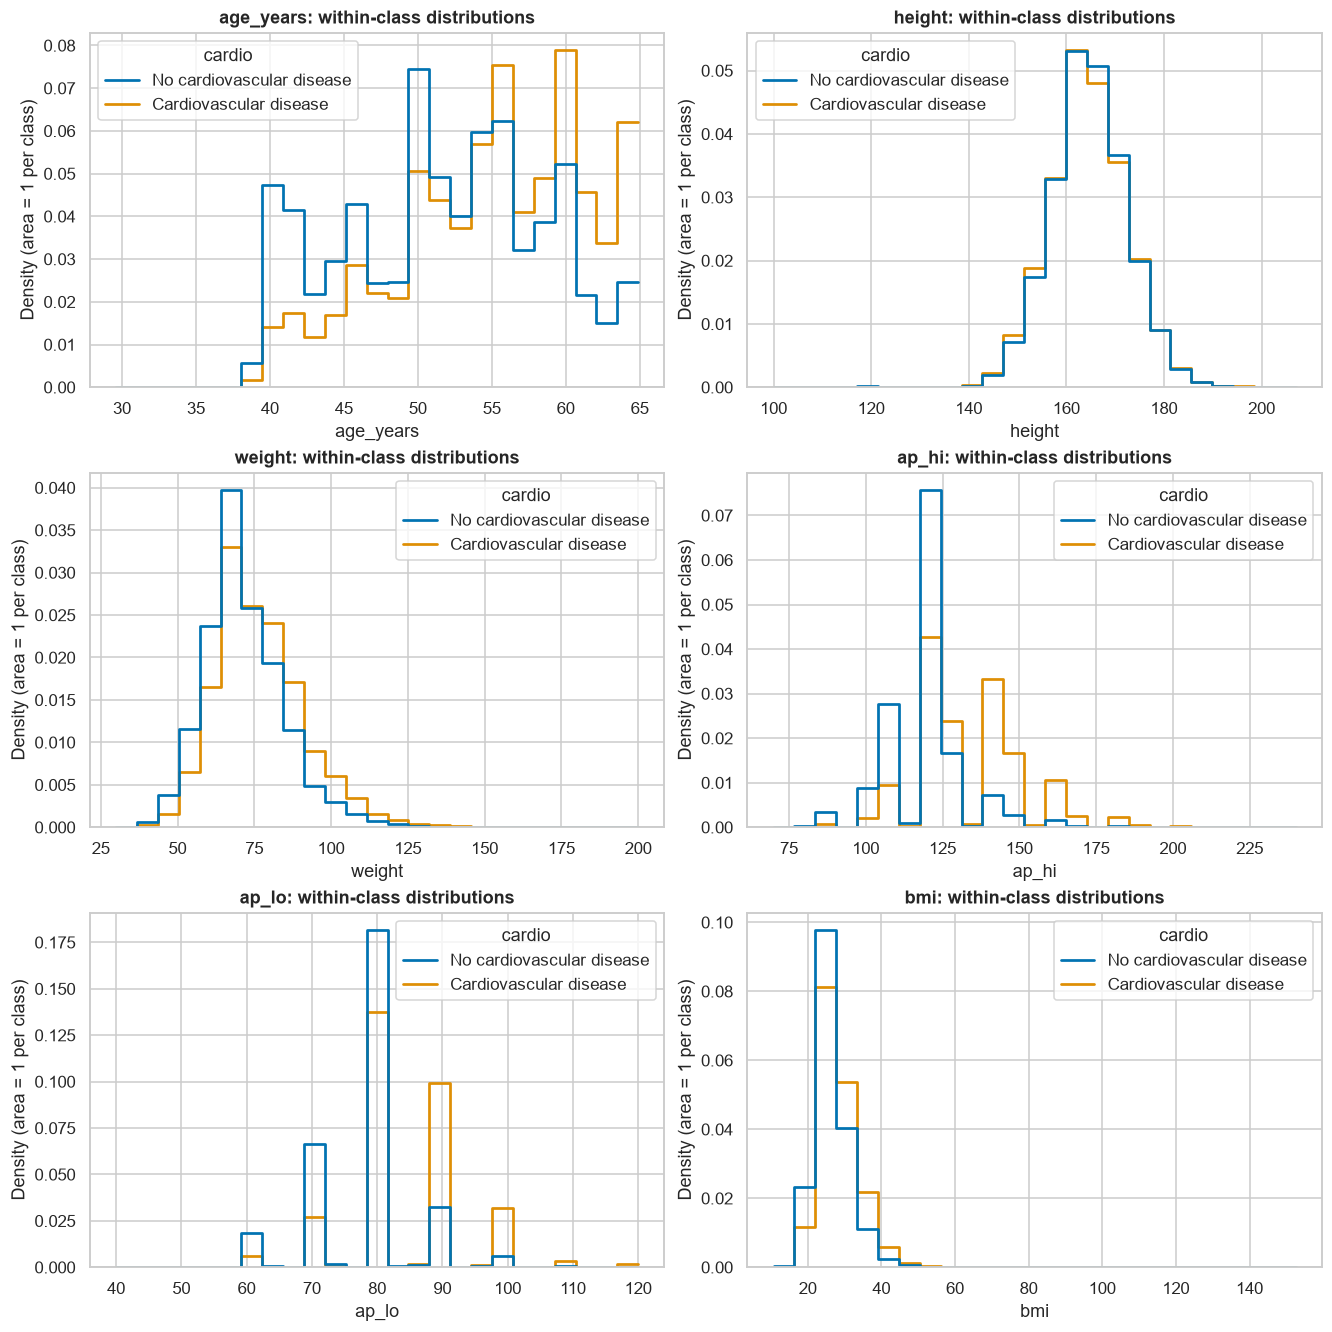

In [38]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(data=df, x=col, hue=CLASS_COL, hue_order=class_order,
                     palette=class_colors, bins=25, stat="density", common_norm=False,
                     common_bins=True, element="step", fill=False, linewidth=1.8, ax=ax)
        ax.set(title=f"{col}: within-class distributions", ylabel="Density (area = 1 per class)")
        if ax.get_legend() is not None:
            ax.get_legend().set_title(TARGET)
    plt.show()

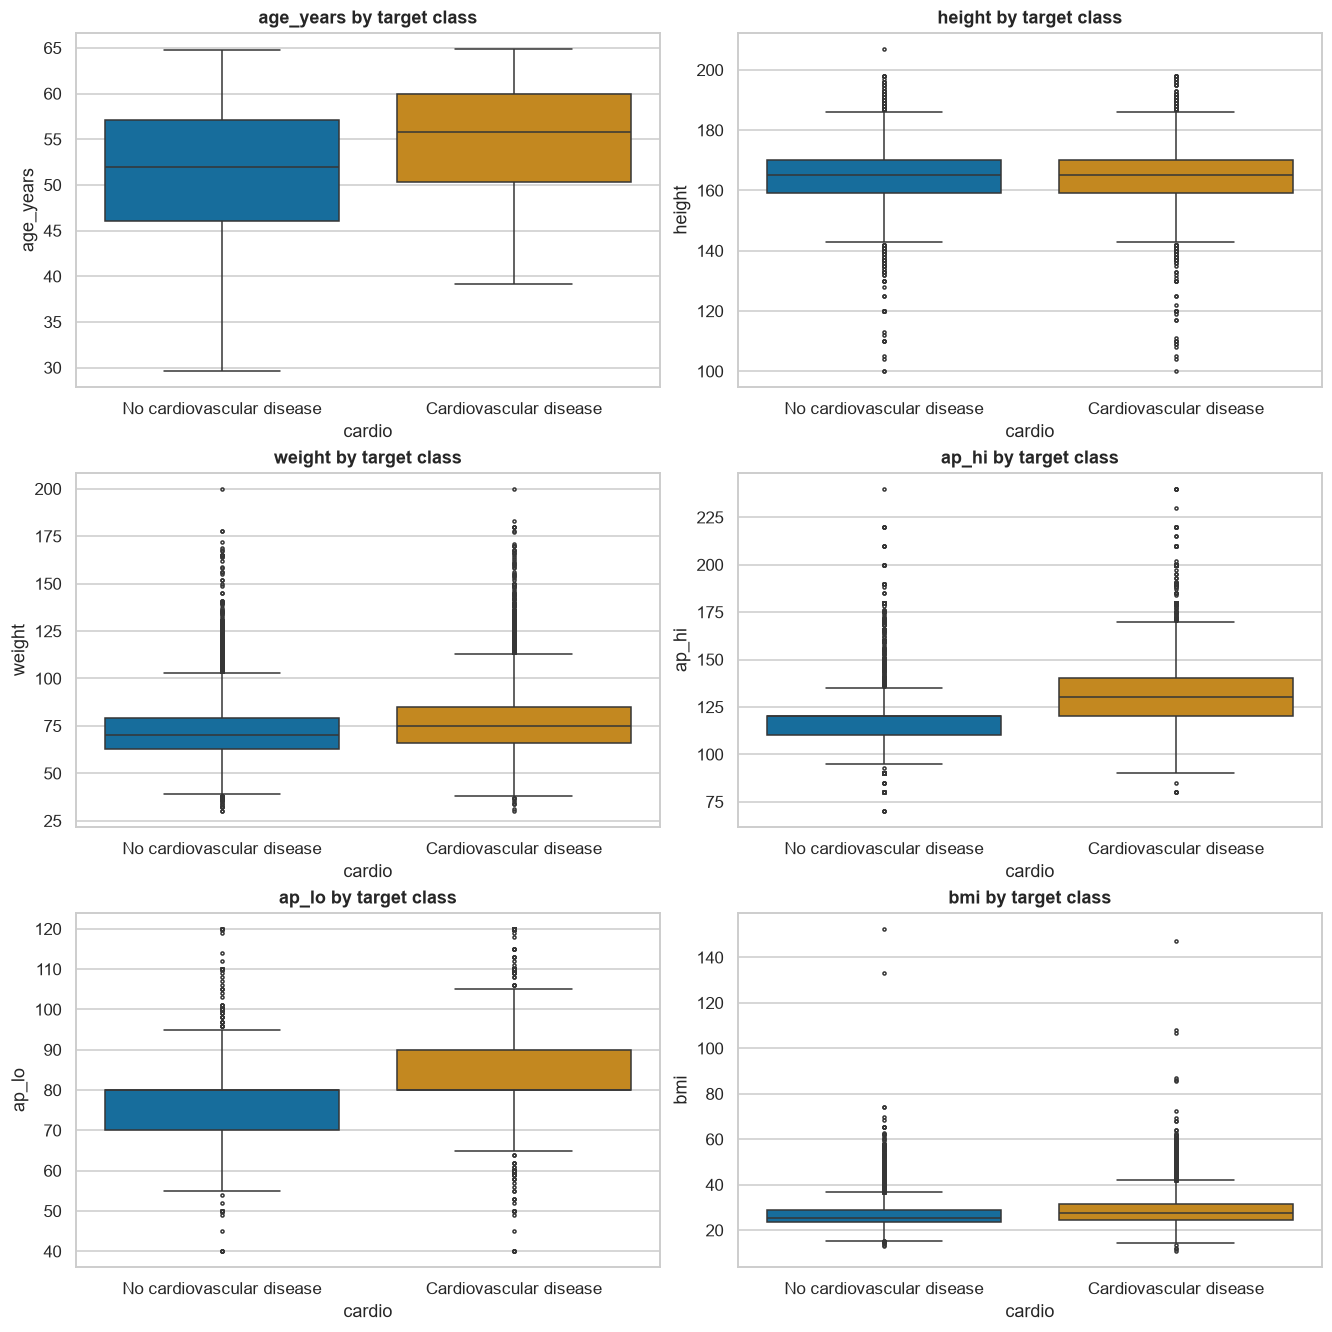

In [39]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(
            data=df, x=CLASS_COL, y=col,
            order=class_order, hue=CLASS_COL,
            palette=class_colors, legend=False,
            fliersize=2, ax=ax
        )
        ax.set(title=f"{col} by target class", xlabel=TARGET)

    plt.show()

**Question:** how do the average and observed extremes differ between target categories?

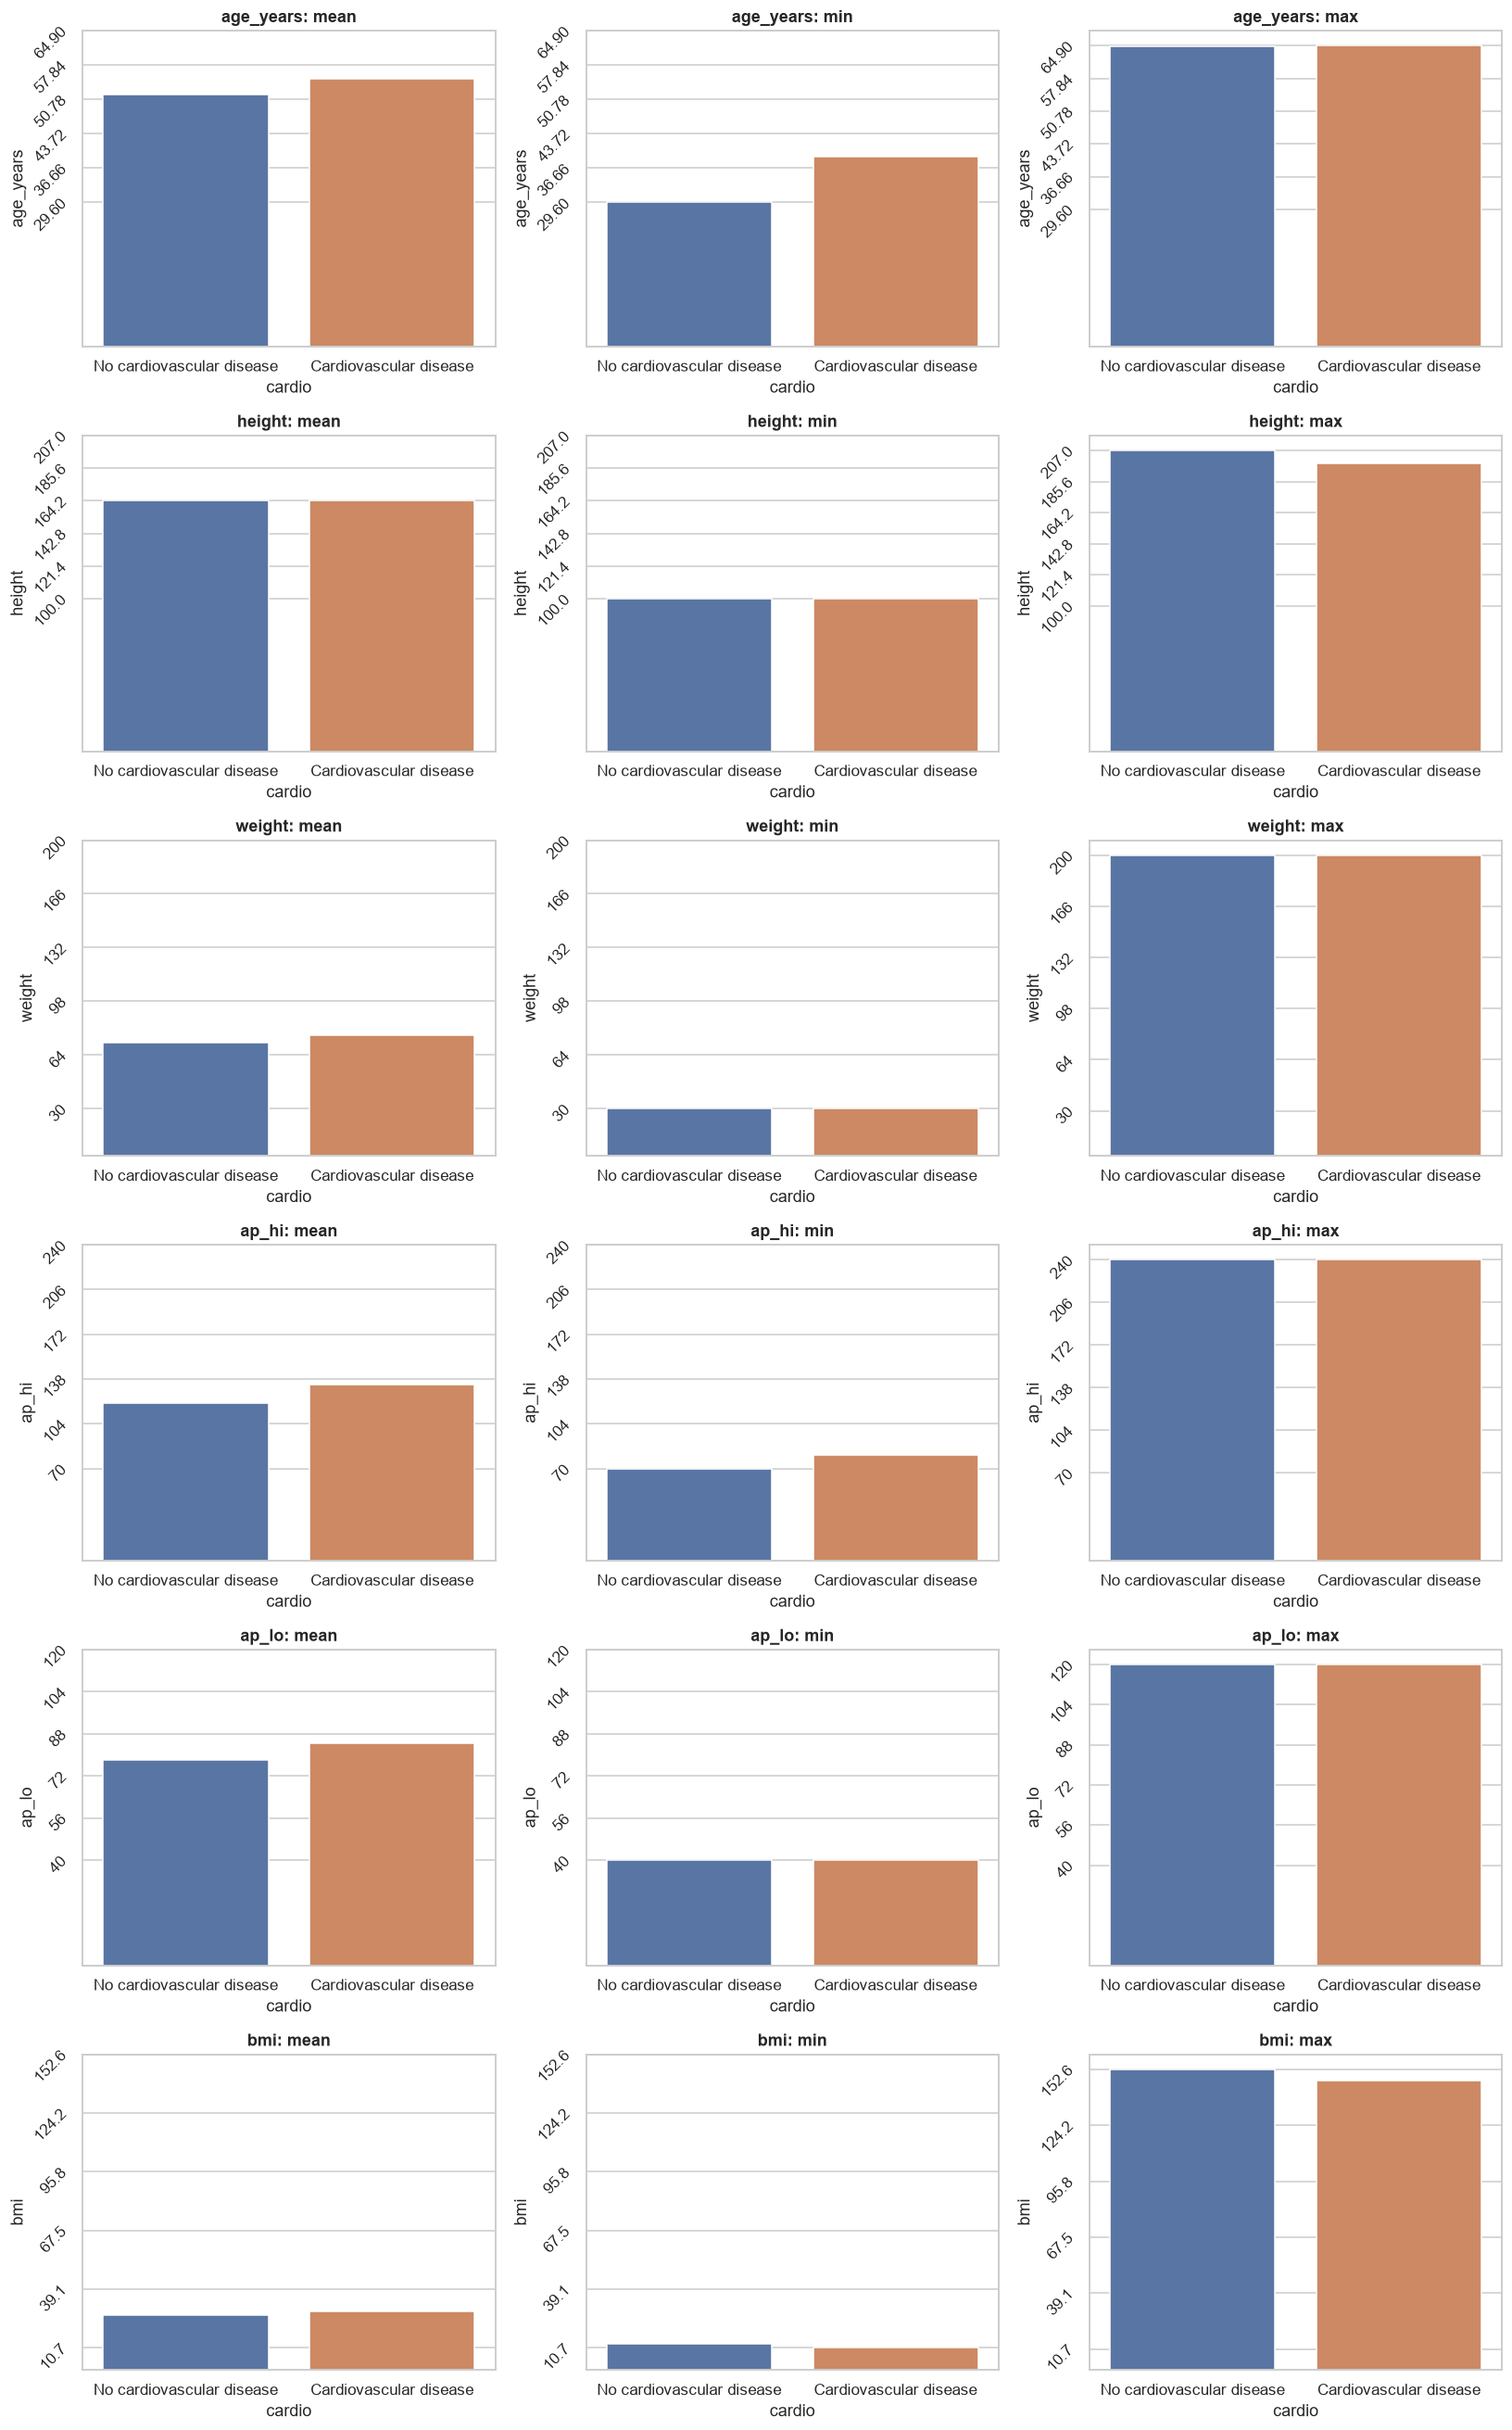

In [41]:
statistics = ["mean", "min", "max"]

plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))

plot_number = 1

for column in NUMERIC_FEATURES:
    for statistic in statistics:

        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)

        min_value = df[column].min()
        max_value = df[column].max()

        sns.barplot(
            data=df,
            x=CLASS_COL,
            y=column,
            hue=CLASS_COL,
            estimator=statistic,
            errorbar=None,
            legend=False
        )

        plt.title(f"{column}: {statistic}")
        plt.xlabel(TARGET)

        plt.yticks(np.linspace(min_value, max_value, 6), rotation=45)

        plot_number += 1

plt.tight_layout()
plt.show()

**Question:** how many rows from each class occur in each category?

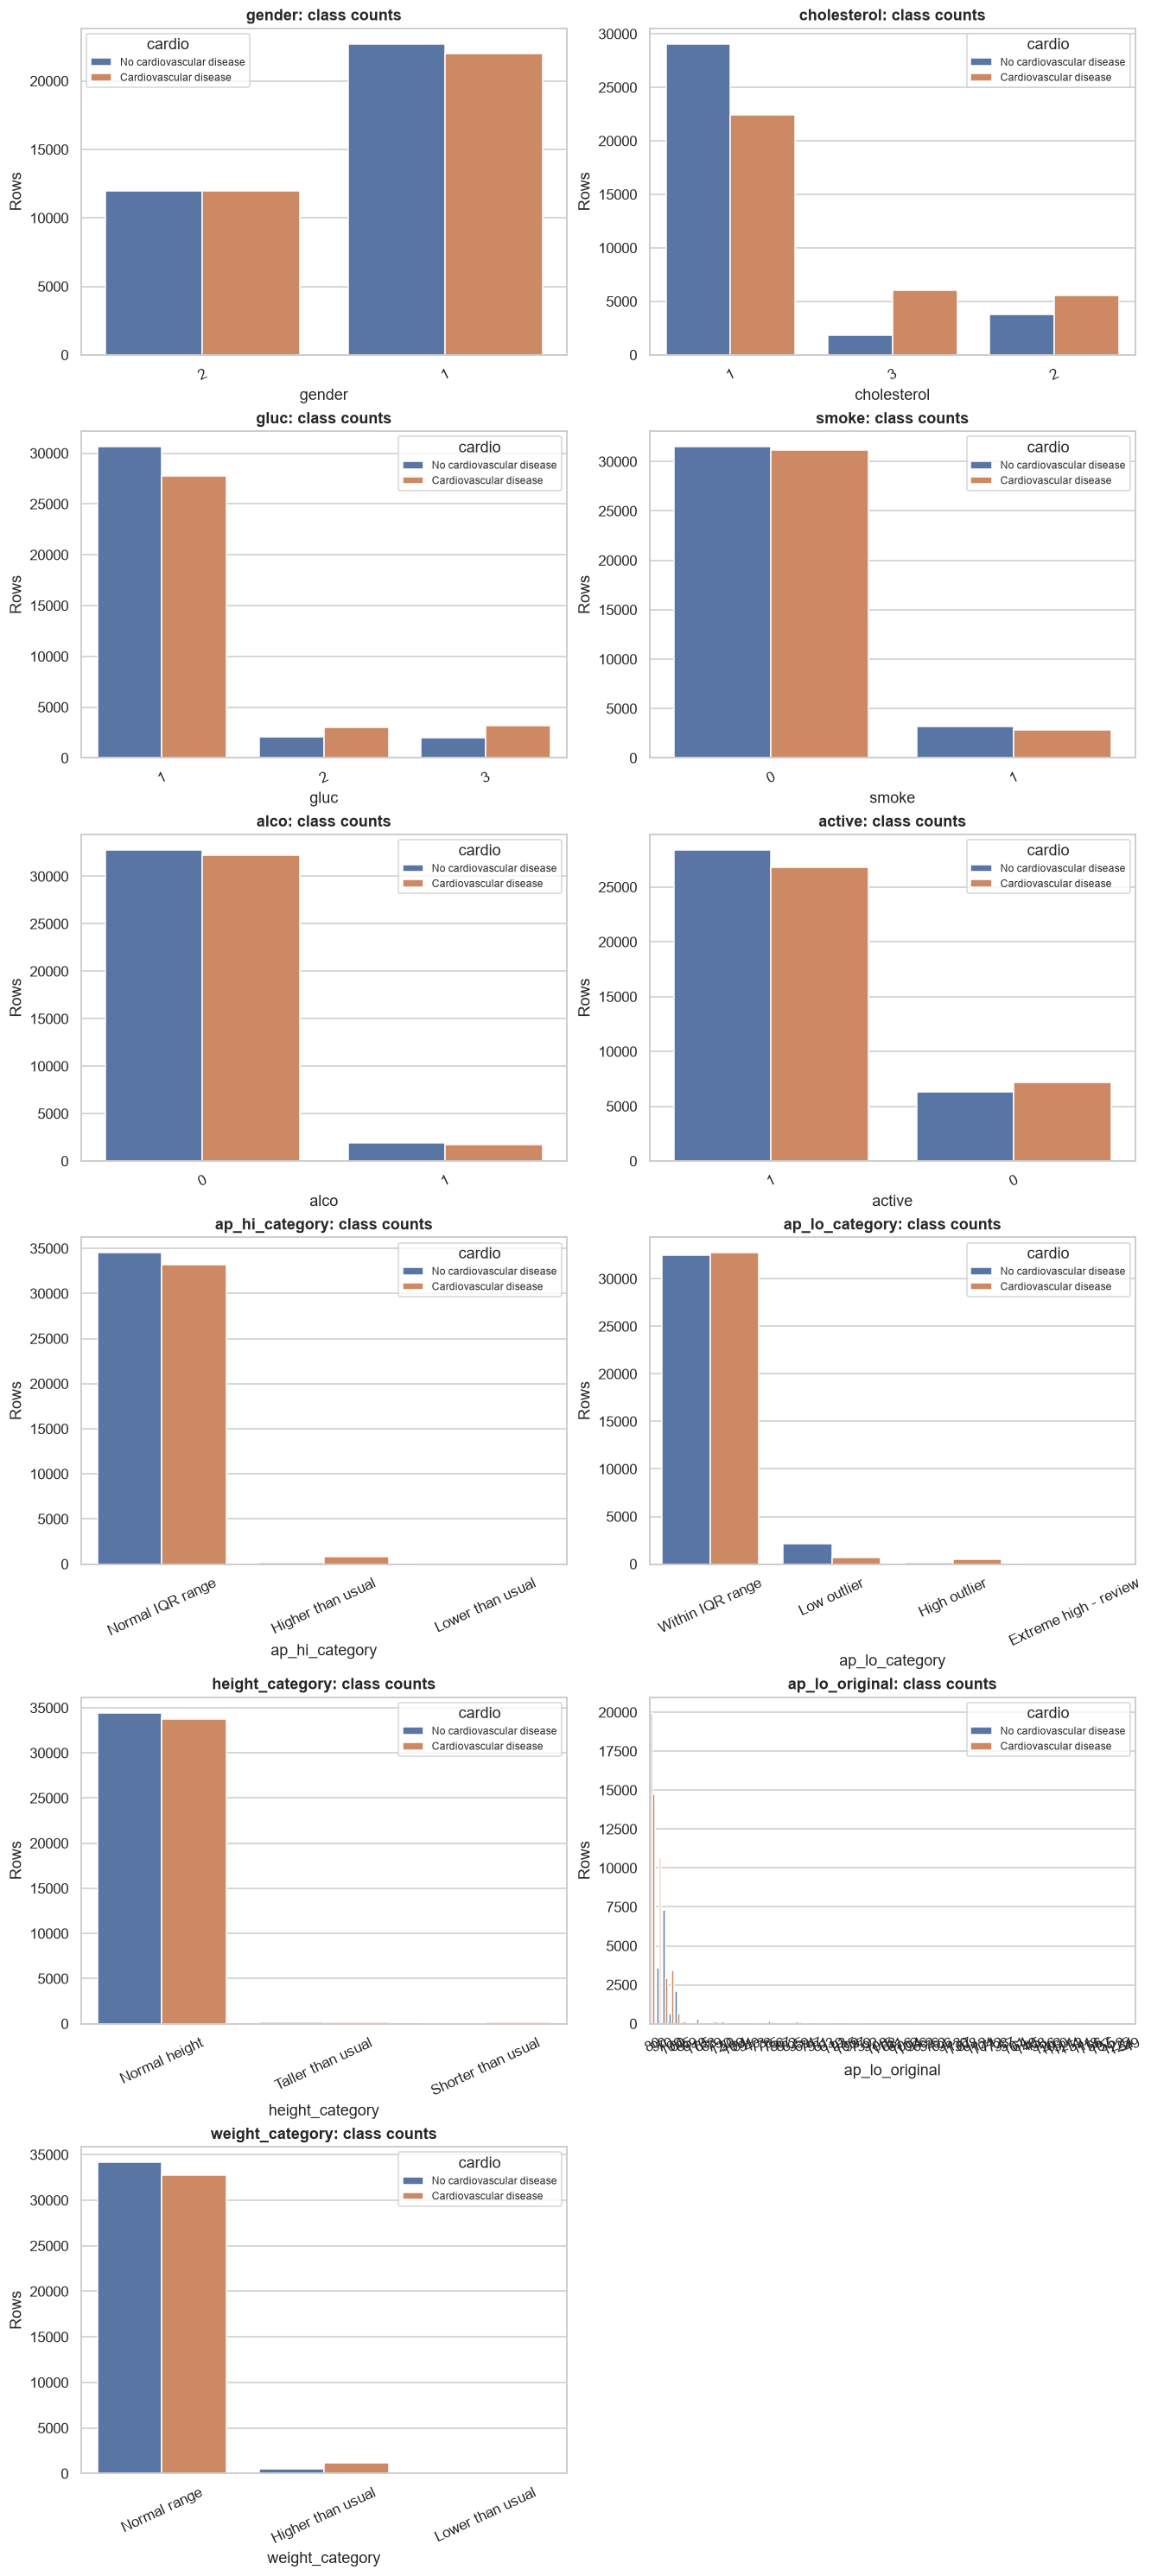

In [42]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.5)
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, x=col, hue=CLASS_COL, ax=ax)
        # , order=category_orders[col],
        # hue_order=class_order, palette=class_colors,
        ax.set(title=f"{col}: class counts", ylabel="Rows")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(title=TARGET, fontsize=8)
    plt.show()

**Question:** among rows in a category, what percentage belongs to each target class?


gender: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
gender,,,,
1,50.79,49.21,44727,False
2,50.05,49.95,23939,False



cholesterol: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
cholesterol,,,,
1,56.46,43.54,51497,False
2,40.37,59.63,9300,False
3,23.74,76.26,7869,False



gluc: percentages within each category


...

__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
ap_lo_category,,,,
Within IQR range,49.79,50.21,65167,False
Low outlier,75.31,24.69,2860,False
High outlier,15.86,84.14,599,False
Extreme high - review,10.00,90.00,40,False



height_category: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
height_category,,,,
Normal height,50.55,49.45,68188,False
Taller than usual,48.84,51.16,258,False
Shorter than usual,46.82,53.18,220,False



weight_category: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
weight_category,,,,
Normal range,51.02,48.98,66927,False
Higher than usual,30.66,69.34,1696,False
Lower than usual,67.44,32.56,43,False


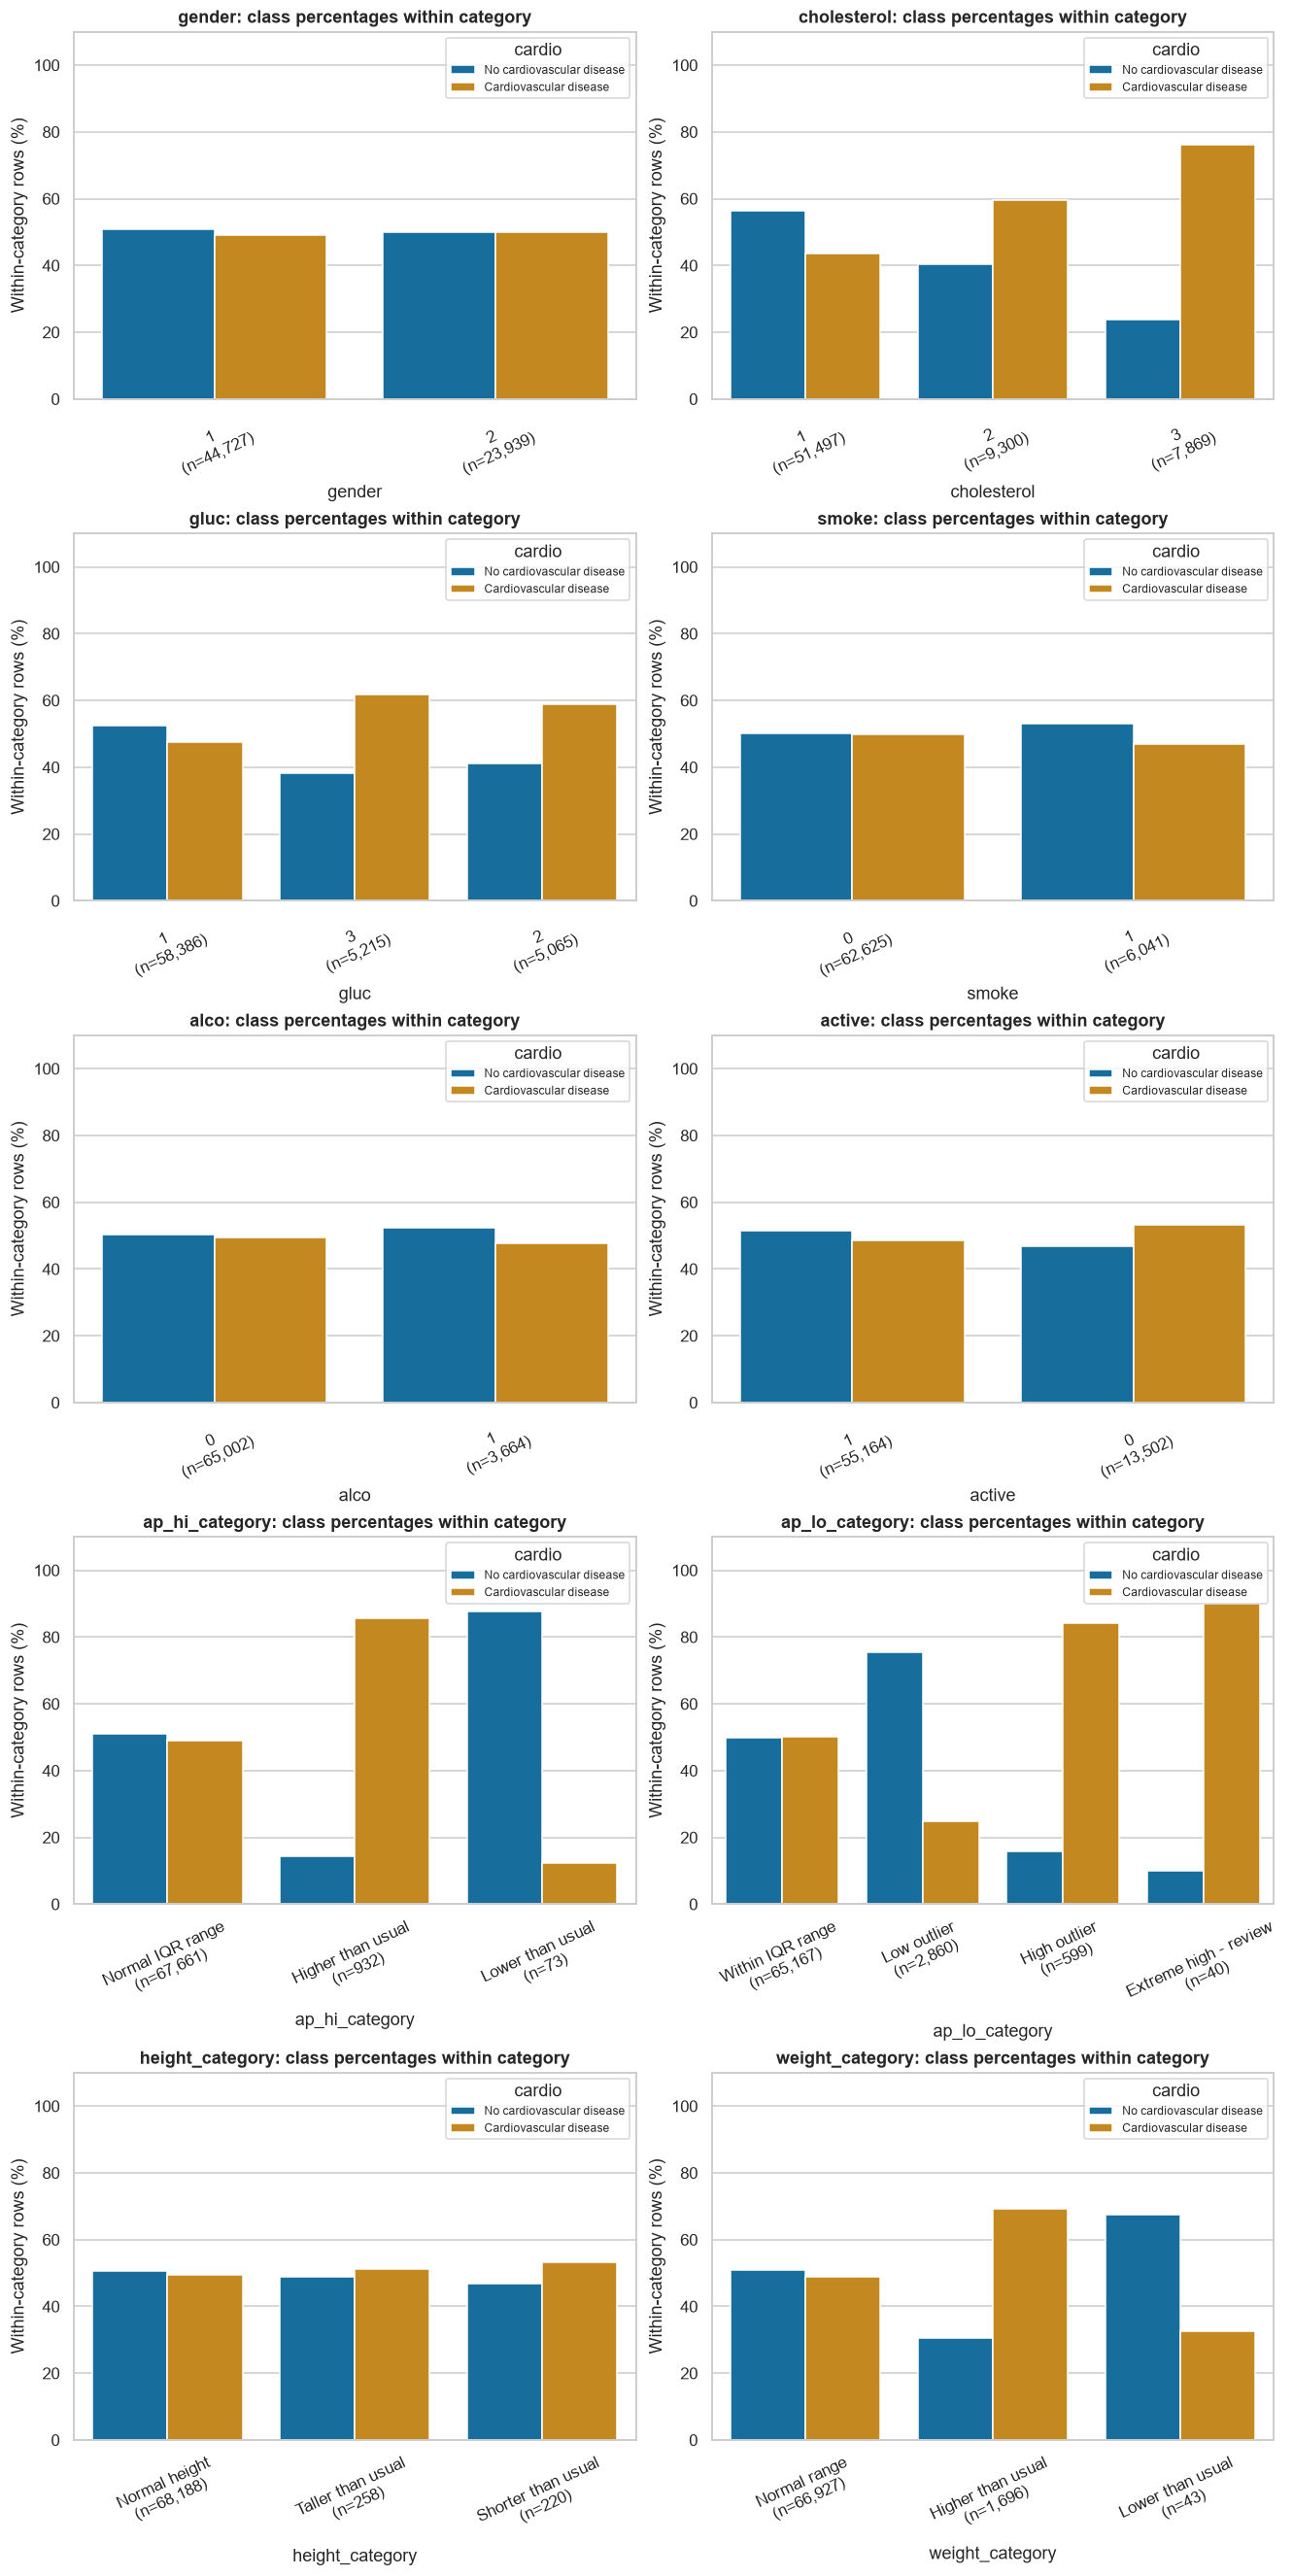

In [44]:
CATEGORICAL_FEATURES_TO_PLOT = [col for col in CATEGORICAL_FEATURES if col != 'ap_lo_original']

category_tables = {}
if CATEGORICAL_FEATURES_TO_PLOT:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES_TO_PLOT), height=4.8)
    for ax, col in zip(axes, CATEGORICAL_FEATURES_TO_PLOT):
        counts = pd.crosstab(df[col], df[CLASS_COL]).reindex(
            index=category_orders[col], columns=class_order, fill_value=0)
        support = counts.sum(axis=1)
        percentages = counts.div(support, axis=0) * 100
        category_tables[col] = (counts, percentages)
        print(f"\n{col}: percentages within each category")
        display(percentages.round(2).assign(n=support, small_group=support < MIN_GROUP_SIZE))

        plot_rates = percentages.rename_axis(index="category", columns="target_class").reset_index()
        plot_rates = plot_rates.melt(id_vars="category", var_name="target_class", value_name="percent")
        sns.barplot(data=plot_rates, x="category", y="percent", hue="target_class",
                    order=category_orders[col], hue_order=class_order,
                    palette=class_colors, errorbar=None, ax=ax)
        ax.set(title=f"{col}: class percentages within category", xlabel=col,
               ylabel="Within-category rows (%)", ylim=(0, 110))
        ax.set_xticks(range(len(support)))
        ax.set_xticklabels([f"{cat}\n(n={support[cat]:,})" for cat in support.index], rotation=25)
        ax.legend(title=TARGET, fontsize=8)
    plt.show()